# HW10 — Improving RAG with Reranking, Chunking, and Conversational Memory

**Dataset:** `ccdv/arxiv-summarization`, `document` config, first 100 documents of the `train` split (the `article` field is indexed).

| Component | Choice |
|---|---|
| Preprocessing | strip `@xmath`/`@xcite` placeholders, re-attach split hyphens and punctuation, collapse whitespace |
| Chunking 1 | **Fixed-size sliding window**: 200 words, 40-word overlap (ignores sentence boundaries) |
| Chunking 2 | **Sentence-aware recursive packing**: whole sentences packed up to 200 words, 1-sentence overlap; run-on "sentences" > 200 words are split into word pieces |
| Embeddings | `BAAI/bge-small-en-v1.5` (384-d, normalized; BGE query instruction prefix on queries) |
| Vector DB | **ChromaDB** `PersistentClient` (`./chroma_db`), one collection per chunking strategy, cosine HNSW |
| Retrieval | top-20 candidates from Chroma by cosine similarity |
| Reranking | cross-encoder `cross-encoder/ms-marco-MiniLM-L-6-v2` re-scores the 20 candidates |
| Memory | `ConversationMemory`: keeps the last 2 user turns and prepends them to a follow-up query (LLM-free query contextualization) |
| Metrics | Precision@K, Recall@K (K = 5, 10), MRR@10 — relevance labelled manually per query (Section 7) |

The helper functions (cleaning, chunkers, memory class, metric functions) live in `rag_core.py` next to this notebook and are printed in Section 0 so the notebook is self-documenting.

## 0. Setup

In [1]:
import os, json, time, hashlib, re, random, platform
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import numpy as np, pandas as pd, torch, chromadb, matplotlib
import matplotlib.pyplot as plt
import sentence_transformers, transformers
from sentence_transformers import SentenceTransformer, CrossEncoder
from rag_core import (clean_text, split_sentences, chunk_fixed, chunk_sentences,
                      ConversationMemory, precision_at_k, recall_at_k, reciprocal_rank)

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)

print("python", platform.python_version(), "| torch", torch.__version__, "| sentence-transformers", sentence_transformers.__version__,
      "| transformers", transformers.__version__, "| chromadb", chromadb.__version__, "| device", DEVICE)

python 3.13.7 | torch 2.11.0 | sentence-transformers 5.4.0 | transformers 5.5.3 | chromadb 1.5.9 | device mps


In [2]:
import inspect, rag_core
print(inspect.getsource(rag_core))

"""Core pieces of the HW10 RAG pipeline (imported by the notebook).

Preprocessing, two chunking strategies, embedding + ChromaDB indexing,
retrieval with/without cross-encoder reranking, a simple conversational
memory, and Precision@K / Recall@K / MRR.
"""
import re

# ----------------------------------------------------------------------------
# 1. Preprocessing
# ----------------------------------------------------------------------------
# The arXiv articles are lower-cased, whitespace-tokenised LaTeX dumps
# ("long - distance", "refs.@xcite", "( @xmath0 )"). Clean them into
# normal prose so both the embedder and the sentence splitter behave.

def clean_text(t: str) -> str:
    t = re.sub(r"@xmath\d+", " ", t)              # inline maths placeholders
    t = re.sub(r"@xcite", " ", t)                 # citation placeholders
    t = re.sub(r"\brefs?\s*\.\s*(?=[\s,.\-]|$)", " ", t)  # dangling "refs ."
    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"\s+-\s+", "-", t)                #

## 1. Load the dataset

`load_dataset(..., streaming=True)` avoids downloading the full ~200k-article dataset; only the first 100 training articles are taken and cached to `data/arxiv_first100.json` so later runs are offline.

In [3]:
CACHE = "data/arxiv_first100.json"
if not os.path.exists(CACHE):
    from datasets import load_dataset
    ds = load_dataset("ccdv/arxiv-summarization", "document", split="train", streaming=True)
    rows = []
    for i, r in enumerate(ds):
        if i >= 100: break
        rows.append({"doc_id": i, "article": r["article"], "abstract": r["abstract"]})
    json.dump(rows, open(CACHE, "w"))
raw = json.load(open(CACHE))
print(len(raw), "documents; fields:", list(raw[0].keys()))
lens = pd.Series([len(r["article"].split()) for r in raw])
print("article length (whitespace tokens): min %d | median %d | max %d | total %d" % (lens.min(), lens.median(), lens.max(), lens.sum()))

100 documents; fields: ['doc_id', 'article', 'abstract']
article length (whitespace tokens): min 604 | median 4847 | max 33095 | total 651653


## 2. Preprocessing

In [4]:
docs = [{"doc_id": r["doc_id"], "text": clean_text(r["article"]), "abstract": clean_text(r["abstract"])} for r in raw]
print("BEFORE:\n", raw[3]["article"][880:1400], "\n")
print("AFTER:\n", docs[3]["text"][800:1250])
before = sum(len(r["article"].split()) for r in raw); after = sum(len(d["text"].split()) for d in docs)
print(f"\nwhitespace tokens: {before:,} -> {after:,}  ({100*(before-after)/before:.1f}% removed: placeholders and detached punctuation)")

BEFORE:
 ffuser introduces an additional phase ( randomly varying in space and time ) to the wave front of the outgoing radiation . statistical characteristics of the random phase determine the initial transverse coherence length of the beam . it is shown in refs . @xcite,@xcite that a considerable decrease in the noise / signal ratio can occur under following conditions : ( i ) the ratio of the initial transverse coherence length , @xmath0 , to the beam radius , @xmath1 , should be essentially smaller than unity ; and ( ii 

AFTER:
 r placed near the exit aperture. this diffuser introduces an additional phase (randomly varying in space and time) to the wave front of the outgoing radiation. statistical characteristics of the random phase determine the initial transverse coherence length of the beam. it is shown in, that a considerable decrease in the noise / signal ratio can occur under following conditions: (i) the ratio of the initial transverse coherence length, to the bea

whitespa

## 3. Two chunking strategies

Both strategies target the same **~200-word** budget so the comparison isolates *where the boundaries fall*, not chunk size.

* **Strategy 1 — fixed-size window:** every 160 words, take the next 200 words. Cheap and uniform, but cuts sentences in half.
* **Strategy 2 — sentence-aware recursive:** split into sentences, pack whole sentences greedily up to 200 words, repeat the last sentence at the start of the next chunk. A run-on "sentence" longer than 200 words (equation or reference dumps) is recursively split into word pieces.

In [5]:
STRATEGIES = {"fixed": chunk_fixed, "sentence": chunk_sentences}
chunks = {}
for name, fn in STRATEGIES.items():
    rows = []
    for d in docs:
        for j, ch in enumerate(fn(d["text"])):
            rows.append({"id": f"{name}-d{d['doc_id']}-c{j}", "doc_id": d["doc_id"], "chunk": j, "text": ch})
    chunks[name] = rows

stats = []
for name, rows in chunks.items():
    w = np.array([len(r["text"].split()) for r in rows])
    ends_clean = np.mean([r["text"].rstrip()[-1] in ".!?" for r in rows])
    stats.append({"strategy": name, "chunks": len(rows), "mean words": w.mean().round(1), "min": w.min(), "max": w.max(),
                  "std": w.std().round(1), "% chunks ending at sentence end": round(100*ends_clean, 1)})
pd.DataFrame(stats)

,strategy,chunks,mean words,min,max,std,% chunks ending at sentence end
0,fixed,3194,197.3,41,200,16.9,8.0
1,sentence,3156,182.3,9,200,23.4,97.9


In [6]:
for name in chunks:
    first = [r for r in chunks[name] if r["doc_id"] == 3][:2]
    print(f"===== {name}: doc 3, chunk 0 (end) | chunk 1 (start) =====")
    print("...", first[0]["text"][-220:])
    print("|", first[1]["text"][:220], "...\n")

===== fixed: doc 3, chunk 0 (end) | chunk 1 (start) =====
... o can occur under following conditions: (i) the ratio of the initial transverse coherence length, to the beam radius, should be essentially smaller than unity; and (ii) the characteristic time of phase variations, should
| decrease in the noise / signal ratio can occur under following conditions: (i) the ratio of the initial transverse coherence length, to the beam radius, should be essentially smaller than unity; and (ii) the characterist ...

===== sentence: doc 3, chunk 0 (end) | chunk 1 (start) =====
... roduces an additional phase (randomly varying in space and time) to the wave front of the outgoing radiation. statistical characteristics of the random phase determine the initial transverse coherence length of the beam.
| statistical characteristics of the random phase determine the initial transverse coherence length of the beam. it is shown in, that a considerable decrease in the noise / signal ratio can occur under f

## 4. Embed and index in ChromaDB

Chunks are embedded with `bge-small-en-v1.5` (L2-normalized) and stored with their text and metadata (`doc_id`, `chunk`) in a persistent ChromaDB collection per strategy. Embeddings are cached to `data/emb_<strategy>_<hash>.npy` (the hash covers the chunk texts, so any change to cleaning/chunking forces a re-embed).

In [7]:
embedder = SentenceTransformer("BAAI/bge-small-en-v1.5", device=DEVICE)
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "   # BGE retrieval instruction
print("max_seq_length:", embedder.max_seq_length)
for name, rows in chunks.items():
    ntok = np.array([len(embedder.tokenizer(r["text"], add_special_tokens=True)["input_ids"]) for r in rows])
    print(f"{name:9s} tokens/chunk: median {int(np.median(ntok))}, max {ntok.max()}, "
          f"{(ntok > 512).sum()} chunks ({100*(ntok > 512).mean():.1f}%) truncated at 512 (math/reference-heavy text)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Token indices sequence length is longer than the specified maximum sequence length for this model (533 > 512). Running this sequence through the model will result in indexing errors


max_seq_length: 512


fixed     tokens/chunk: median 279, max 1808, 145 chunks (4.5%) truncated at 512 (math/reference-heavy text)


sentence  tokens/chunk: median 261, max 1687, 129 chunks (4.1%) truncated at 512 (math/reference-heavy text)


In [8]:
client = chromadb.PersistentClient(path="chroma_db")
collections = {}
for name, rows in chunks.items():
    h = hashlib.sha1("\n".join(r["text"] for r in rows).encode()).hexdigest()[:10]
    path = f"data/emb_{name}_{h}.npy"
    t0 = time.time()
    if os.path.exists(path):
        E = np.load(path)
    else:
        E = embedder.encode([r["text"] for r in rows], batch_size=32, normalize_embeddings=True, show_progress_bar=False)
        np.save(path, E)
    t_emb = time.time() - t0
    try: client.delete_collection(name)
    except Exception: pass
    col = client.create_collection(name, metadata={"hnsw:space": "cosine"})
    for s in range(0, len(rows), 1000):
        b = rows[s:s+1000]
        col.add(ids=[r["id"] for r in b], documents=[r["text"] for r in b],
                metadatas=[{"doc_id": r["doc_id"], "chunk": r["chunk"]} for r in b],
                embeddings=E[s:s+1000].tolist())
    collections[name] = col
    print(f"{name:9s}: {col.count()} vectors of dim {E.shape[1]} in ChromaDB collection '{name}'  (embedding {t_emb:.0f}s{' from cache' if t_emb < 5 else ''})")

fixed    : 3194 vectors of dim 384 in ChromaDB collection 'fixed'  (embedding 0s from cache)


sentence : 3156 vectors of dim 384 in ChromaDB collection 'sentence'  (embedding 0s from cache)


## 5. Retrieval with and without reranking

* **No reranking:** the top-K of Chroma's cosine-similarity ranking.
* **With reranking:** take Chroma's top-20 candidates, score each (query, chunk) pair with the cross-encoder, and re-sort by that score. The cross-encoder reads query and passage *together* (full attention between them), which is more precise than comparing two independently computed vectors, but too slow to run over the whole collection — hence retrieve-then-rerank.

In [9]:
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", device=DEVICE)
N_CANDIDATES = 20

def retrieve(query, strategy, rerank=False, k=10, n_candidates=N_CANDIDATES):
    qv = embedder.encode([QUERY_PREFIX + query], normalize_embeddings=True).tolist()
    res = collections[strategy].query(query_embeddings=qv, n_results=n_candidates, include=["documents", "metadatas", "distances"])
    hits = [{"id": i, "doc_id": m["doc_id"], "text": t, "cos_sim": 1 - dist}
            for i, t, m, dist in zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0])]
    if rerank:
        scores = reranker.predict([(query, h["text"]) for h in hits], show_progress_bar=False)
        for h, s in zip(hits, scores): h["ce_score"] = float(s)
        hits = sorted(hits, key=lambda h: -h["ce_score"])
    return hits[:k]

def show(hits, k=5, width=150):
    for r, h in enumerate(hits[:k], 1):
        extra = f" ce={h['ce_score']:+.2f}" if "ce_score" in h else ""
        print(f"  {r}. [doc {h['doc_id']:>2}] cos={h['cos_sim']:.3f}{extra} | {h['text'][:width]}...")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 6. Queries and manual relevance definition

**Single-turn evaluation queries (10).** Each targets one paper in the 100-document corpus (the *gold* document, chosen by reading the abstracts). Queries are phrased as a user would ask them, without copying the abstract wording.

**Relevance (defined manually, per the assignment).** A chunk is *relevant* if it is useful for answering the query. For each query I wrote that down as a rule **before looking at any retrieval output**: the chunk must come from the gold paper **and** contain the answer-bearing concept(s), expressed as regular expressions that must *all* match (e.g. for the ratchet query the chunk must discuss both *current reversal* and *bifurcation*). A chunk of the right paper that only covers, say, its experimental setup is therefore *not* relevant. Applying the rule to every chunk in the collection gives the number of relevant chunks, which is the denominator of Recall@K.

**Hand review.** After a first run I read every chunk that any configuration put in a top-5 (Section 11) and corrected the rules in two ways, both applied identically to both chunking strategies: (a) `MANUAL_INCLUDE` adds answer-bearing passages the keywords missed because they paraphrase the key term (e.g. the bend-loss formula is written as "attenuation"/"power-decay"); (b) bibliography chunks are never relevant (8 reference-list chunks of the original Q4 paper had matched on paper titles).

**Q4 was replaced.** The original Q4 asked why second-harmonic generation is enhanced in SiC nanopillars (doc 6). The review showed that doc 6's `article` field holds only the paper's *supplementary material* (simulation setup + references; it cites "eq. (1) in the main manuscript"). Once reference lists were excluded, the corpus had 0–1 chunks that answer the question, so the query measured a dataset defect rather than retrieval. It was replaced by a question on doc 72, whose rule was written before running it. All numbers below are after the review and the replacement; the first-run numbers are recorded in `METRICS.md`.

In [10]:
QUERIES = {
  "Q1":  {"q": "How does a random phase diffuser reduce the scintillation of a laser beam?",               "gold": [3],  "must": [r"diffuser", r"scintillation"]},
  "Q2":  {"q": "What learning rates do regularized kernel methods achieve for additive models?",           "gold": [0],  "must": [r"learning rate|rate of convergence|rates? of", r"additive"]},
  "Q3":  {"q": "How can an origin-destination matrix of public transport passengers be estimated from survey data?", "gold": [32], "must": [r"survey", r"\bod\b|origin"]},
  "Q4":  {"q": "How can gamma-ray bursts be calibrated as distance indicators without assuming a cosmological model?", "gold": [72], "must": [r"calibrat", r"interpolat|cosmology-independent|cosmology independent|model-independent|circular"]},
  "Q5":  {"q": "How can quantum error correction deal with fully correlated noise?",                       "gold": [28], "must": [r"correlated", r"error|encod|codeword"]},
  "Q6":  {"q": "Are current reversals in a deterministic ratchet caused by bifurcations?",                 "gold": [2],  "must": [r"current reversal|reversal", r"bifurcation"]},
  "Q7":  {"q": "How can bend loss be predicted for a large-mode-area photonic crystal fiber?",             "gold": [37], "must": [r"bend", r"loss"]},
  "Q8":  {"q": "How can astronomy libraries make online resources accessible to users with disabilities?", "gold": [40], "must": [r"accessib|disabilit|wcag|section 508|screen reader"]},
  "Q9":  {"q": "How are axoplasmic reticula automatically annotated in electron microscopy images?",       "gold": [67], "must": [r"axoplasmic|reticul", r"filter|region growing|annotat|segment|pipeline"]},
  "Q10": {"q": "Which network topologies work best for network-on-chip turbo decoders?",                  "gold": [99], "must": [r"topolog", r"decod|noc|network"]},
}

# Multi-turn conversations: turn 2 is deliberately under-specified ("it", "this model", "they")
# and only makes sense given turn 1.
CONVERSATIONS = {
  "C1": [{"q": "What is the statefinder diagnostic used for in torsion cosmology?",            "gold": [26], "must": [r"statefinder"]},
         {"q": "What best-fit parameter values did they get when fitting it to supernova data?", "gold": [26], "must": [r"best fit|best-fit|fit", r"supernova|sne|essence"]}],
  "C2": [{"q": "What is known about the cool polluted white dwarf NLTT 19868?",                    "gold": [41], "must": [r"nltt 19868|19868"]},
         {"q": "Which elements show up in its spectrum, and how abundant is iron?",               "gold": [41], "must": [r"calcium|\bca\b|magnesium|\bmg\b|alumin|\bal\b", r"iron|\bfe\b"]}],
  "C3": [{"q": "Why do stronger solar cycles have shorter rise times?",                           "gold": [57], "must": [r"waldmeier|rise time"]},
         {"q": "Can the same model also reproduce grand minima?",                                 "gold": [57], "must": [r"grand minim"]}],
  "C4": [{"q": "How can a magnetic tunnel junction mimic a biological synapse?",                  "gold": [7],  "must": [r"\bmtj|magnetic tunnel", r"synap"]},
         {"q": "How does the frequency of the input affect whether it shows long-term potentiation?", "gold": [7], "must": [r"frequen", r"\bltp\b|long-term|potentiation"]}],
  "C5": [{"q": "What is the multi-resolution bead-spring model for polymer dynamics?",            "gold": [83], "must": [r"bead", r"resolution|rouse"]},
         {"q": "How does it change the resolution on the fly?",                                   "gold": [83], "must": [r"resolution", r"metropolis|on-the-fly|on the fly|chang"]}],
}

# --- Corrections made after hand-reading the pooled top-5 results (Section 11) -----------------
# (a) Answer-bearing passages that the keyword rule missed because they paraphrase the key term.
#     Given as a phrase, so every chunk of the gold paper containing it (in EITHER chunking strategy)
#     becomes relevant, and the Recall denominators of both strategies change consistently.
MANUAL_INCLUDE = {
    "Q1": ["phase diffuser placed near the exit aperture",          # intro: diffuser makes the beam partially coherent -> lower noise/signal
           "considerable decrease in the noise / signal ratio"],    # the two conditions under which the diffuser works
    "Q3": ["estimate the approximate whole matrix structure"],      # the paper's own survey-based estimator (no 'od'/'origin' in the chunk)
    "Q5": ["all the qubits in the register suffer from the same error operator"],  # = fully correlated noise, and the n-1 / n-2 encoding result
    "Q7": ["in the large-mode area limit we get"],                  # the bend-loss (power-decay) formula itself ('attenuation', not 'loss')
    "Q8": ["plenty of assistive technologies exist"],               # assistive technology / DAISY talking-book standard
}
for qid, phrases in MANUAL_INCLUDE.items():
    QUERIES[qid]["include"] = phrases

# (b) Bibliography chunks are never useful for answering a question, even when reference *titles*
#     contain the query terms (this produced 8 false positives for Q4). Applied to every query.
def is_reference_list(text):
    return len(re.findall(r"\*\s*(?:19|20)\d\d\s*\*|\bpp\.\s*\d", text)) >= 3

def is_relevant(spec, chunk_id, doc_id, text):
    if doc_id not in spec["gold"] or is_reference_list(text):
        return 0
    if any(p in text for p in spec.get("include", [])):
        return 1
    return int(all(re.search(p, text) for p in spec["must"]))

def n_relevant(spec, strategy):
    return sum(is_relevant(spec, r["id"], r["doc_id"], r["text"]) for r in chunks[strategy])

all_specs = {**{k: v for k, v in QUERIES.items()}, **{f"{c}-T{t+1}": turn for c, turns in CONVERSATIONS.items() for t, turn in enumerate(turns)}}
pd.DataFrame([{"query": k, "gold doc": v["gold"], "rule (all must match)": " AND ".join(v["must"]),
               "relevant chunks (fixed)": n_relevant(v, "fixed"), "relevant chunks (sentence)": n_relevant(v, "sentence")}
              for k, v in all_specs.items()])

,query,gold doc,rule (all must match),relevant chunks (fixed),relevant chunks (sentence)
0,Q1,[3],diffuser AND scintillation,8,9
1,Q2,[0],learning rate|rate of convergence|rates? of AND additive,15,16
2,Q3,[32],survey AND \bod\b|origin,7,6
3,Q4,[72],calibrat AND interpolat|cosmology-independent|cosmology independent|model-independent|circular,22,25
4,Q5,[28],correlated AND error|encod|codeword,6,6
5,Q6,[2],current reversal|reversal AND bifurcation,16,15
6,Q7,[37],bend AND loss,4,4
7,Q8,[40],accessib|disabilit|wcag|section 508|screen reader,12,11
8,Q9,[67],axoplasmic|reticul AND filter|region growing|annotat|segment|pipeline,5,5
9,Q10,[99],topolog AND decod|noc|network,4,4


## 7. Sample queries — retrieval **without** reranking

Two sample queries (Q6 and Q9) on both chunking strategies; `cos` is the cosine similarity from ChromaDB, `✓` marks chunks judged relevant.

In [11]:
def show_eval(qid, spec, strategy, rerank, k=5, query=None):
    hits = retrieve(query or spec["q"], strategy, rerank=rerank, k=k)
    for r, h in enumerate(hits, 1):
        rel = "✓" if is_relevant(spec, h["id"], h["doc_id"], h["text"]) else " "
        extra = f" ce={h['ce_score']:+5.2f}" if "ce_score" in h else ""
        print(f"  {r}. {rel} [doc {h['doc_id']:>2}] cos={h['cos_sim']:.3f}{extra} | {h['text'][:120]}...")

SAMPLE = ["Q6", "Q9"]
for qid in SAMPLE:
    for strat in STRATEGIES:
        print(f"\n### {qid} | {strat} | NO rerank: {QUERIES[qid]['q']}")
        show_eval(qid, QUERIES[qid], strat, rerank=False)


### Q6 | fixed | NO rerank: Are current reversals in a deterministic ratchet caused by bifurcations?


  1. ✓ [doc  2] cos=0.871 | possible to have current reversals in the absence of bifurcations from chaos to periodic behavior as well as bifurcation...
  2. ✓ [doc  2] cos=0.854 | do in this paper. we report here on studies on the properties of the current in a chaotic deterministic ratchet, specifi...
  3. ✓ [doc  2] cos=0.841 | change is close to the bifurcation point. this result, that there are situations where the heuristics simply do not seem...
  4. ✓ [doc  2] cos=0.814 | ratchets, it would still be extremely useful to have general heuristic rules such as this. these organizing principles w...
  5. ✓ [doc  2] cos=0.812 | diagram.,title = "fig:",width = 302] it is possible to find several examples of this at different parameters, leading to...

### Q6 | sentence | NO rerank: Are current reversals in a deterministic ratchet caused by bifurcations?
  1. ✓ [doc  2] cos=0.843 | however, we do find evidence for a generalized version of mateos s conjecture. that is, in general, bifurca

## 8. The same queries **with** cross-encoder reranking

In [12]:
for qid in SAMPLE:
    for strat in STRATEGIES:
        print(f"\n### {qid} | {strat} | WITH rerank: {QUERIES[qid]['q']}")
        show_eval(qid, QUERIES[qid], strat, rerank=True)


### Q6 | fixed | WITH rerank: Are current reversals in a deterministic ratchet caused by bifurcations?


  1. ✓ [doc  2] cos=0.871 ce=+6.68 | possible to have current reversals in the absence of bifurcations from chaos to periodic behavior as well as bifurcation...
  2. ✓ [doc  2] cos=0.854 ce=+4.72 | do in this paper. we report here on studies on the properties of the current in a chaotic deterministic ratchet, specifi...
  3. ✓ [doc  2] cos=0.814 ce=+4.59 | ratchets, it would still be extremely useful to have general heuristic rules such as this. these organizing principles w...
  4. ✓ [doc  2] cos=0.841 ce=+4.15 | change is close to the bifurcation point. this result, that there are situations where the heuristics simply do not seem...
  5. ✓ [doc  2] cos=0.803 ce=+4.00 | sea itself may get pinched off or otherwise changed, or attractors can change symmetry or bifurcate. this means that the...

### Q6 | sentence | WITH rerank: Are current reversals in a deterministic ratchet caused by bifurcations?


  1. ✓ [doc  2] cos=0.814 ce=+4.92 | we consider the impact of different kinds of ensembles of particles on the current and show that the current depends sig...
  2. ✓ [doc  2] cos=0.827 ce=+4.49 | this means that the transport properties can change dramatically as well. a few years ago, mateos considered a specific ...
  3. ✓ [doc  2] cos=0.819 ce=+3.96 | however, arguably, although subjective, this change is close to the bifurcation point. this result, that there are situa...
  4. ✓ [doc  2] cos=0.843 ce=+3.60 | however, we do find evidence for a generalized version of mateos s conjecture. that is, in general, bifurcations for tra...
  5. ✓ [doc  2] cos=0.806 ce=+3.50 | the second is that the heuristic that arises from this is again a negative conclusion, that * (ii) not all current rever...

### Q9 | fixed | WITH rerank: How are axoplasmic reticula automatically annotated in electron microscopy images?


  1. ✓ [doc 67] cos=0.827 ce=+4.65 | the open connectome project (located at http://openconnecto.me) aims to annotate all the features in a 3d volume of neur...
  2. ✓ [doc 67] cos=0.828 ce=+3.48 | to verify their correctness and identify axoplasmic reticula that were missed initially. for each slice, we traverse the...
  3. ✓ [doc 67] cos=0.809 ce=+3.01 | is greater, and no change in areas of constant intensity. hence, we use the 3x3 laplacian filter to highlight edges arou...
  4. ✓ [doc 67] cos=0.806 ce=+1.34 | to detect transverally sliced axoplasmic reticula. in future work, we plan to extend our morphological region growing al...
  5. ✓ [doc 67] cos=0.662 ce=-4.08 | non-linear filter consisting of one 2d gaussian kernel, which decays with spatial distance, and one 1d gaussian kernel, ...

### Q9 | sentence | WITH rerank: How are axoplasmic reticula automatically annotated in electron microscopy images?


  1. ✓ [doc 67] cos=0.830 ce=+4.65 | the open connectome project (located at http://openconnecto.me) aims to annotate all the features in a 3d volume of neur...
  2. ✓ [doc 67] cos=0.814 ce=+3.99 | for each slice, we traverse the annotations and check if an axoplasmic reticulum is present in the corresponding xy-loca...
  3. ✓ [doc 67] cos=0.815 ce=+3.31 | hence, we use the 3x3 laplacian filter to highlight edges around dark features such as axoplasmic reticula. we use a mor...
  4. ✓ [doc 67] cos=0.767 ce=+1.13 | in future work, we plan to extend our morphological region growing algorithm to also find dilated axoplasmic reticula, a...
  5. ✓ [doc 67] cos=0.624 ce=-4.81 | the bilateral filter is a non-linear filter consisting of one 2d gaussian kernel, which decays with spatial distance, an...


## 9. Conversational memory

`ConversationMemory` (in `rag_core.py`) stores each user turn and the chunk ids retrieved for it. Before retrieving for a new turn, `contextualize()` prepends the last `max_turns = 2` user queries to the new query, so a follow-up such as *"How does it change the resolution on the fly?"* is embedded (and reranked) as *"What is the multi-resolution bead-spring model for polymer dynamics? How does it change the resolution on the fly?"*. This is the simplest form of history-aware query rewriting and needs no LLM; an LLM-based rewriter ("condense question") is the usual upgrade.

### 9a. Multi-turn demo (conversation C5, sentence chunking, reranked)

In [13]:
class ChatRetriever:
    def __init__(self, strategy, rerank, use_memory, max_turns=2):
        self.strategy, self.rerank, self.use_memory = strategy, rerank, use_memory
        self.memory = ConversationMemory(max_turns=max_turns)
    def ask(self, query, k=10):
        effective = self.memory.contextualize(query) if self.use_memory else query
        hits = retrieve(effective, self.strategy, rerank=self.rerank, k=k)
        self.memory.add(query, [h["id"] for h in hits])
        return effective, hits

def demo(conv_id, strategy="sentence", rerank=True):
    turns = CONVERSATIONS[conv_id]
    for use_mem in (False, True):
        bot = ChatRetriever(strategy, rerank, use_mem)
        print(f"\n================ {conv_id} | memory {'ON' if use_mem else 'OFF'} ================")
        for t, turn in enumerate(turns, 1):
            eff, hits = bot.ask(turn["q"])
            print(f"Turn {t} user: {turn['q']}")
            if eff != turn["q"]: print(f"   -> query sent to retriever: {eff}")
            for r, h in enumerate(hits[:3], 1):
                rel = "✓" if is_relevant(turn, h["id"], h["doc_id"], h["text"]) else " "
                print(f"   {r}. {rel} [doc {h['doc_id']:>2}] {h['text'][:110]}...")
demo("C5")


================ C5 | memory OFF ================


Turn 1 user: What is the multi-resolution bead-spring model for polymer dynamics?
   1. ✓ [doc 83] a multi-resolution bead-spring polymer of size consists of a chain of beads of radius, for, connected by sprin...
   2. ✓ [doc 83] [defomr] let us consider a bead-spring polymer consisting of beads of radius connected by springs with the kuh...
   3. ✓ [doc 83] lemma [lemconsnum] shows that the multi-resolution bead-spring model is a generalization of the rouse model. i...


Turn 2 user: How does it change the resolution on the fly?
   1.   [doc 24] rotational invariance in 2-d is achieved by using rotationally symmetric operators. the key idea for the desig...
   2.   [doc 24] furthermore, turns out to be completely specified in terms of the _ original _ image function and its derivati...
   3.   [doc 24] invariants are a popular concept in object recognition and image retrieval. they aim to provide descriptions t...

================ C5 | memory ON ================


Turn 1 user: What is the multi-resolution bead-spring model for polymer dynamics?
   1. ✓ [doc 83] a multi-resolution bead-spring polymer of size consists of a chain of beads of radius, for, connected by sprin...
   2. ✓ [doc 83] [defomr] let us consider a bead-spring polymer consisting of beads of radius connected by springs with the kuh...
   3. ✓ [doc 83] lemma [lemconsnum] shows that the multi-resolution bead-spring model is a generalization of the rouse model. i...


Turn 2 user: How does it change the resolution on the fly?
   -> query sent to retriever: What is the multi-resolution bead-spring model for polymer dynamics? How does it change the resolution on the fly?
   1.   [doc 83] [defomr] let us consider a bead-spring polymer consisting of beads of radius connected by springs with the kuh...
   2.   [doc 83] lemma [lemconsnum] shows that the multi-resolution bead-spring model is a generalization of the rouse model. i...
   3. ✓ [doc 83] we also study the appropriate choice of timesteps for numerical simulations of the model and support our analy...


### 9b. A second demo (C2: the pronoun *its* refers to the white dwarf from turn 1)

In [14]:
demo("C2")


================ C2 | memory OFF ================


Turn 1 user: What is known about the cool polluted white dwarf NLTT 19868?
   1. ✓ [doc 41] the abundance ratio observed in the nltt 888 is only second to that of the cool dz white dwarf sdss j1043 + 35...
   2. ✓ [doc 41] concentrating our efforts on the hydrogen-rich sample may help establish whether their environment is similar ...
   3. ✓ [doc 41] this mass corresponds to less than one thousandth of the mass of the earth. the same diffusion scenario, but e...


Turn 2 user: Which elements show up in its spectrum, and how abundant is iron?
   1. ✓ [doc 41] the predominance of core iron material implies the likely presence of the, yet undetected, core elements such ...
   2.   [doc 96] among detected and abundant molecules, only co and nh satisfy this criterion. chemical equilibrium calculation...
   3. ✓ [doc 41] [fig_ratio] (bottom panel) also shows the fe / ca abundance ratio for stars with a measurable iron abundance. ...

================ C2 | memory ON ================


Turn 1 user: What is known about the cool polluted white dwarf NLTT 19868?
   1. ✓ [doc 41] the abundance ratio observed in the nltt 888 is only second to that of the cool dz white dwarf sdss j1043 + 35...
   2. ✓ [doc 41] concentrating our efforts on the hydrogen-rich sample may help establish whether their environment is similar ...
   3. ✓ [doc 41] this mass corresponds to less than one thousandth of the mass of the earth. the same diffusion scenario, but e...


Turn 2 user: Which elements show up in its spectrum, and how abundant is iron?
   -> query sent to retriever: What is known about the cool polluted white dwarf NLTT 19868? Which elements show up in its spectrum, and how abundant is iron?
   1. ✓ [doc 41] concentrating our efforts on the hydrogen-rich sample may help establish whether their environment is similar ...
   2. ✓ [doc 41] this mass corresponds to less than one thousandth of the mass of the earth. the same diffusion scenario, but e...
   3. ✓ [doc 41] the abundance ratio observed in the nltt 888 is only second to that of the cool dz white dwarf sdss j1043 + 35...


## 10. Evaluation — Precision@K, Recall@K, MRR

Every query is run through all four retrieval configurations (2 chunking strategies × reranking off/on). The memory comparison uses the **second turn** of each conversation (turn 1 is identical with and without memory) across the same four configurations.

* **Precision@K** = relevant chunks in the top K / K
* **Recall@K** = relevant chunks in the top K / all relevant chunks in that strategy's collection
* **MRR@10** = mean over queries of 1 / rank of the first relevant chunk (0 if none in the top 10)

In [15]:
KS = (5, 10)

def score(spec, hits, strategy):
    rel = [is_relevant(spec, h["id"], h["doc_id"], h["text"]) for h in hits]
    nrel = n_relevant(spec, strategy)
    row = {"n_rel": nrel, "MRR@10": reciprocal_rank(rel, 10)}
    for k in KS:
        row[f"P@{k}"] = precision_at_k(rel, k); row[f"R@{k}"] = recall_at_k(rel, k, nrel)
    return row

METRIC_COLS = ["P@5", "R@5", "P@10", "R@10", "MRR@10"]
rows = []
for strat in STRATEGIES:
    for rr in (False, True):
        for qid, spec in QUERIES.items():
            hits = retrieve(spec["q"], strat, rerank=rr, k=10)
            rows.append({"query": qid, "strategy": strat, "rerank": rr, **score(spec, hits, strat)})
single = pd.DataFrame(rows)
summary_single = single.groupby(["strategy", "rerank"])[METRIC_COLS].mean().round(3)
summary_single

P@5    R@5  P@10   R@10  MRR@10
strategy rerank                                  
fixed    False   0.88  0.580  0.64  0.758    1.00
         True    0.88  0.580  0.68  0.803    1.00
sentence False   0.90  0.591  0.69  0.804    0.95
         True    0.88  0.595  0.70  0.837    1.00

In [16]:
# per-query detail
single.pivot_table(index="query", columns=["strategy", "rerank"], values=["P@5", "MRR@10"]).round(2).reindex(list(QUERIES))

MRR@10                        P@5                     
strategy  fixed       sentence       fixed       sentence      
rerank    False True     False True  False True     False True 
query                                                          
Q1          1.0   1.0      1.0   1.0   1.0   0.6      1.0   0.8
Q2          1.0   1.0      1.0   1.0   1.0   1.0      1.0   1.0
Q3          1.0   1.0      1.0   1.0   1.0   1.0      1.0   1.0
Q4          1.0   1.0      1.0   1.0   0.8   1.0      1.0   0.8
Q5          1.0   1.0      0.5   1.0   0.8   0.8      0.8   0.8
Q6          1.0   1.0      1.0   1.0   1.0   1.0      1.0   1.0
Q7          1.0   1.0      1.0   1.0   0.8   0.8      0.8   0.8
Q8          1.0   1.0      1.0   1.0   1.0   1.0      1.0   1.0
Q9          1.0   1.0      1.0   1.0   0.8   1.0      0.8   1.0
Q10         1.0   1.0      1.0   1.0   0.6   0.6      0.6   0.6

### 10a. Without vs with conversational memory (turn-2 follow-ups)

In [17]:
rows = []
for strat in STRATEGIES:
    for rr in (False, True):
        for mem in (False, True):
            for cid, turns in CONVERSATIONS.items():
                bot = ChatRetriever(strat, rr, mem)
                bot.ask(turns[0]["q"])                       # turn 1 (same either way)
                eff, hits = bot.ask(turns[1]["q"])           # turn 2 (depends on turn 1)
                rows.append({"conv": cid, "strategy": strat, "rerank": rr, "memory": mem, **score(turns[1], hits, strat)})
conv = pd.DataFrame(rows)
summary_mem = conv.groupby(["memory", "strategy", "rerank"])[METRIC_COLS].mean().round(3)
summary_mem

P@5    R@5  P@10   R@10  MRR@10
memory strategy rerank                                  
False  fixed    False   0.40  0.242  0.28  0.349   0.629
                True    0.44  0.282  0.26  0.327   0.800
       sentence False   0.36  0.231  0.22  0.289   0.600
                True    0.32  0.211  0.26  0.337   0.600
True   fixed    False   0.40  0.342  0.44  0.673   0.617
                True    0.48  0.399  0.44  0.679   0.750
       sentence False   0.48  0.378  0.40  0.639   0.767
                True    0.56  0.465  0.46  0.766   0.867

In [18]:
conv.pivot_table(index="conv", columns=["memory", "strategy", "rerank"], values="P@5").round(2)

memory   False                      True                      
strategy fixed       sentence       fixed       sentence      
rerank   False True     False True  False True     False True 
conv                                                          
C1         0.8   0.8      0.2   0.4   0.2   0.2      0.4   0.4
C2         0.2   0.2      0.6   0.4   0.4   0.6      0.6   0.8
C3         0.0   0.2      0.0   0.0   0.4   0.6      0.4   0.4
C4         1.0   1.0      1.0   0.8   0.6   0.6      0.8   0.8
C5         0.0   0.0      0.0   0.0   0.4   0.4      0.2   0.4

### 10b. Memory failure mode: a topic switch

Memory is not free. If the user changes topic, prepending the old turn drags retrieval back to the previous paper. Below, turn 1 is about polymers (C5) and turn 2 is the unrelated Q10 (turbo decoders).

In [19]:
rows = []
for strat in STRATEGIES:
    for rr in (False, True):
        for mem in (False, True):
            bot = ChatRetriever(strat, rr, mem)
            bot.ask(CONVERSATIONS["C5"][0]["q"])
            eff, hits = bot.ask(QUERIES["Q10"]["q"])
            rows.append({"strategy": strat, "rerank": rr, "memory": mem, **score(QUERIES["Q10"], hits, strat),
                         "top-5 doc ids": [h["doc_id"] for h in hits[:5]]})
topic_switch = pd.DataFrame(rows)
topic_switch

,strategy,rerank,memory,n_rel,MRR@10,P@5,R@5,P@10,R@10,top-5 doc ids
0,fixed,False,False,4,1.0,0.6,0.75,0.3,0.75,"[99, 99, 99, 99, 99]"
1,fixed,False,True,4,0.0,0.0,0.00,0.0,0.00,"[83, 83, 83, 83, 83]"
2,fixed,True,False,4,1.0,0.6,0.75,0.4,1.00,"[99, 99, 99, 99, 99]"
3,fixed,True,True,4,0.0,0.0,0.00,0.0,0.00,"[83, 83, 83, 83, 83]"
4,sentence,False,False,4,1.0,0.6,0.75,0.4,1.00,"[99, 99, 99, 99, 99]"
5,sentence,False,True,4,0.0,0.0,0.00,0.0,0.00,"[83, 83, 83, 83, 83]"
6,sentence,True,False,4,1.0,0.6,0.75,0.4,1.00,"[99, 99, 99, 99, 99]"
7,sentence,True,True,4,0.0,0.0,0.00,0.0,0.00,"[83, 83, 83, 83, 83]"


### 10c. Headline comparisons

P@5    R@5   P@10   R@10  MRR@10
Reranking (10 queries × 2 strategies)                without reranking           0.89  0.585  0.665  0.781   0.975
                                                     with reranking              0.88  0.588  0.690  0.820   1.000
Chunking (10 queries × rerank off/on)                strategy 1: fixed window    0.88  0.580  0.660  0.781   1.000
                                                     strategy 2: sentence-aware  0.89  0.593  0.695  0.821   0.975
Memory (5 follow-ups × 2 strategies × rerank off/on) without memory              0.38  0.242  0.255  0.325   0.657
                                                     with memory                 0.48  0.396  0.435  0.689   0.750

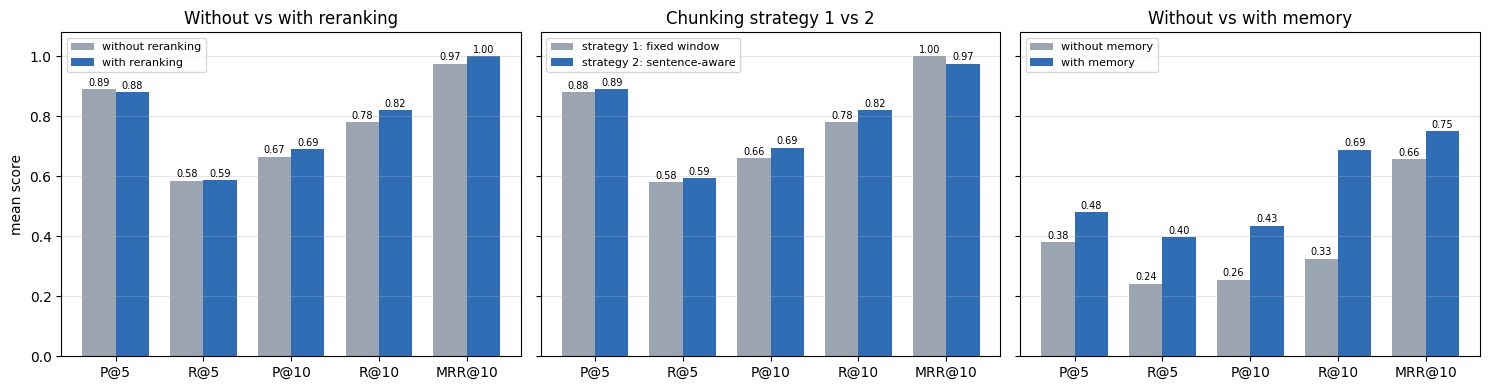

In [20]:
def mean_over(df, by):
    return df.groupby(by)[METRIC_COLS].mean().round(3)

cmp_rerank = mean_over(single, "rerank").rename(index={False: "without reranking", True: "with reranking"})
cmp_chunk  = mean_over(single, "strategy").rename(index={"fixed": "strategy 1: fixed window", "sentence": "strategy 2: sentence-aware"})
cmp_mem    = mean_over(conv, "memory").rename(index={False: "without memory", True: "with memory"})
headline = pd.concat({"Reranking (10 queries × 2 strategies)": cmp_rerank,
                      "Chunking (10 queries × rerank off/on)": cmp_chunk,
                      "Memory (5 follow-ups × 2 strategies × rerank off/on)": cmp_mem})
display(headline)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, df) in zip(axes, [("Without vs with reranking", cmp_rerank), ("Chunking strategy 1 vs 2", cmp_chunk),
                                  ("Without vs with memory", cmp_mem)]):
    x = np.arange(len(METRIC_COLS)); w = 0.38
    for i, (lab, vals) in enumerate(df.iterrows()):
        b = ax.bar(x + (i - 0.5) * w, vals.values, w, label=lab, color=["#9aa5b1", "#2f6db5"][i])
        ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
    ax.set_xticks(x, METRIC_COLS); ax.set_title(title); ax.set_ylim(0, 1.08); ax.legend(fontsize=8, loc="upper left")
    ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("mean score")
plt.tight_layout(); plt.savefig("figures/headline_comparison.png", dpi=150); plt.show()

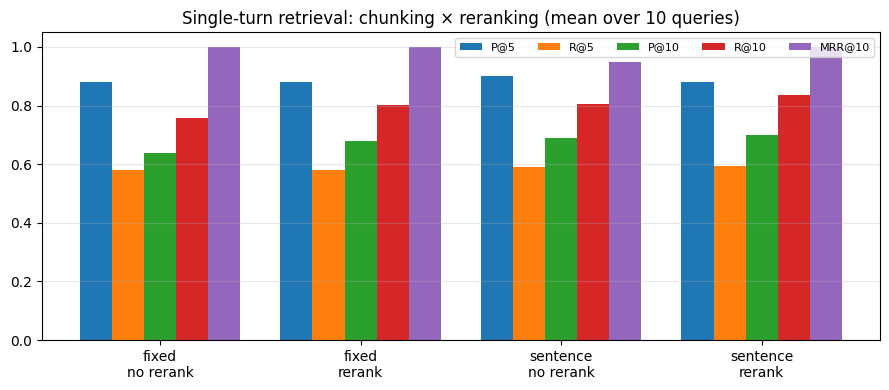

In [21]:
# All four single-turn configurations side by side
fig, ax = plt.subplots(figsize=(9, 4))
cfgs = summary_single.reset_index()
labels = [f"{s}\n{'rerank' if r else 'no rerank'}" for s, r in zip(cfgs.strategy, cfgs.rerank)]
x = np.arange(len(cfgs)); w = 0.16
for i, m in enumerate(METRIC_COLS):
    ax.bar(x + (i - 2) * w, cfgs[m], w, label=m)
ax.set_xticks(x, labels); ax.set_ylim(0, 1.05); ax.legend(ncol=5, fontsize=8); ax.grid(axis="y", alpha=.3)
ax.set_title("Single-turn retrieval: chunking × reranking (mean over 10 queries)")
plt.tight_layout(); plt.savefig("figures/single_turn_configs.png", dpi=150); plt.show()

## 11. Relevance audit (hand review of the labels)

For every single-turn query, the top-5 chunks returned by each configuration are pooled, and the label is printed beside the text so the rule-based judgments can be checked by reading. This review is what produced `MANUAL_INCLUDE` and the bibliography rule in Section 6.

In [22]:
audit = []
for qid, spec in QUERIES.items():
    pool = {}
    for strat in STRATEGIES:
        for rr in (False, True):
            for h in retrieve(spec["q"], strat, rerank=rr, k=5):
                pool[h["id"]] = h
    for cid, h in pool.items():
        audit.append({"query": qid, "chunk": cid, "doc": h["doc_id"], "label": is_relevant(spec, cid, h["doc_id"], h["text"]), "text": h["text"][:160]})
audit = pd.DataFrame(audit)
print(f"{len(audit)} pooled (query, chunk) pairs; {audit.label.sum()} labelled relevant; "
      f"{(audit.doc.isin(sum([v['gold'] for v in QUERIES.values()], [])) & (audit.label == 0)).sum()} from a gold paper but labelled NOT relevant")
audit[audit["query"].isin(["Q1", "Q6"])]

119 pooled (query, chunk) pairs; 103 labelled relevant; 12 from a gold paper but labelled NOT relevant


,query,chunk,doc,label,text
0,Q1,fixed-d3-c17,3,1,is very convenient for theoretial analysis because only two parameters are required to describe the effects of the d...
1,Q1,fixed-d3-c2,3,1,phase diffuser may become unacceptably high. the factors mentioned above impose serious restrictions on the physical...
2,Q1,fixed-d3-c0,3,1,studies of laser beams propagating through turbulent atmospheres are important for many applications such as remote ...
3,Q1,fixed-d3-c16,3,1,"distribution function,. hence, four-wave correlations determine the value of scintillation index. the main effect of..."
4,Q1,fixed-d3-c13,3,1,is a simple explanation for this phenomenon: the noise generated by the turbulence is complemented by the noise aris...
5,Q1,fixed-d3-c11,3,0,"detector) and (fast detector), respectively. there is a specific realization of the diffuser in which a random phase..."
6,Q1,fixed-d3-c8,3,0,"the phase diffuser, a factor or should be inserted into the integrand of eq. [fourteen]. the quantity is the random ..."
7,Q1,sentence-d3-c16,3,1,"in contrast, and depend on two wave-correlations, both waves being given at the same instant. therefore, the values ..."
8,Q1,sentence-d3-c2,3,1,"besides that, in some specific cases (see, for example,), the spectral broadening of laser radiation due to the phas..."
9,Q1,sentence-d3-c17,3,1,"[twtw].) our results show the importance of both parameters, and, on the ability of a phase diffuser to suppress sci..."


In [23]:
# chunks from the gold paper that the rule rejected: the most informative cases to review
gold_rejected = audit[(audit.label == 0) & audit.apply(lambda r: r["doc"] in QUERIES[r["query"]]["gold"], axis=1)]
gold_rejected

,query,chunk,doc,label,text
5,Q1,fixed-d3-c11,3,0,"detector) and (fast detector), respectively. there is a specific realization of the diffuser in which a random phase..."
6,Q1,fixed-d3-c8,3,0,"the phase diffuser, a factor or should be inserted into the integrand of eq. [fourteen]. the quantity is the random ..."
12,Q1,sentence-d3-c11,3,0,"in what follows, we will see that these two limiting cases have physical interpretations where where (slow detector)..."
37,Q4,fixed-d72-c4,72,0,"in many works by combining the 69 grb data with sne ia and the other cosmological probes, such as the cmb anisotropy..."
49,Q4,sentence-d72-c1,72,0,"however, the maximum redshift of the sne ia which we can currently use is only about 1.7, whereas fluctuations of th..."
52,Q5,fixed-d28-c0,28,0,"in quantum information processing, information is stored and processed with a quantum system. a quantum system is al..."
56,Q5,sentence-d28-c0,28,0,"in quantum information processing, information is stored and processed with a quantum system. a quantum system is al..."
77,Q7,fixed-d37-c4,37,0,"get in the relevant limit where. here, and in eqs. ([alpha_lma]) and ([v_pcf]) have been introduced. for large-mode ..."
112,Q10,fixed-d99-c10,99,0,"no. 5, pp. 232234, feb 2002. m. j. thul, f. gilbert, and n. wehn, `` optimized concurrent interleaving architecture ..."
113,Q10,fixed-d99-c0,99,0,in the last years wireless communication systems coped with the problem of delivering reliable information while gra...


In [24]:
single.to_csv("data/results_single_turn.csv", index=False); conv.to_csv("data/results_memory.csv", index=False)
headline.to_csv("data/results_headline.csv"); audit.to_csv("data/relevance_audit.csv", index=False)
print("saved results to data/*.csv and figures/*.png")

saved results to data/*.csv and figures/*.png


## 12. Findings and comparison

All numbers are from the run above (Section 10). Mean over queries; K = 5 and 10; MRR is MRR@10.

| Comparison | Setting | P@5 | R@5 | P@10 | R@10 | MRR |
|---|---|---|---|---|---|---|
| **Reranking** (10 queries × 2 strategies) | without | 0.89 | 0.585 | 0.665 | 0.781 | 0.975 |
| | with | 0.88 | 0.588 | **0.690** | **0.820** | **1.000** |
| **Chunking** (10 queries × rerank off/on) | 1: fixed window | 0.88 | 0.580 | 0.660 | 0.781 | 1.000 |
| | 2: sentence-aware | 0.89 | 0.593 | **0.695** | **0.821** | 0.975 |
| **Memory** (5 follow-ups × 2 strategies × rerank off/on) | without | 0.38 | 0.242 | 0.255 | 0.325 | 0.657 |
| | with | **0.48** | **0.396** | **0.435** | **0.689** | **0.750** |

Best single-turn configuration: **sentence-aware + reranking** (P@10 0.70, R@10 0.837, MRR 1.00). Best for follow-ups: **sentence-aware + reranking + memory** (P@5 0.56, R@10 0.766, MRR 0.867, against 0.32 / 0.337 / 0.600 for the same configuration without memory).

### Without vs with reranking
* The bi-encoder alone already puts a relevant chunk first for almost every query (MRR 0.975). The queries target one distinctive paper each in a 100-paper corpus, so finding the right *paper* is easy. Reranking's job is ordering chunks *within* that paper, and it lifts **P@10 by +0.025 and R@10 by +0.039** and makes MRR perfect (it fixes Q5 under sentence chunking, where a generic QEC intro chunk had been ranked first). Per query and strategy, P@10 improved in 9 cases, was unchanged in 8 and got worse in 3.
* At **P@5 it is a wash (0.89 → 0.88)**. The clearest loss is Q1 on fixed chunks (P@5 1.0 → 0.6). The cross-encoder *promoted* equation-heavy derivation chunks (c8, c10, c11) that repeat the words "phase diffuser" but are mostly LaTeX remnants, and *demoted* the explanatory chunks c2 and c13, which say what the diffuser does to intensity fluctuations. The MS-MARCO cross-encoder was trained on web search queries, not physics papers, so it leans on surface word overlap when the text is unfamiliar.
* Cost: about 20 cross-encoder passes per query, still well under a second per query here.

### Chunking strategy 1 (fixed window) vs 2 (sentence-aware)
* Both make about 3,150 chunks of about 190 words, so the comparison isolates boundary placement: 98% of sentence-aware chunks end at a sentence boundary, against 8% of fixed-window chunks.
* Sentence-aware chunking is **slightly better at depth (P@10 +0.035, R@10 +0.040)**, and better or equal on R@10 in 14 of 20 query × rerank cases. A chunk that holds complete sentences carries one coherent claim, which both the embedder and the cross-encoder score more reliably than a window that starts mid-sentence.
* At the top it is a tie (P@5 0.88 vs 0.89; MRR 1.000 vs 0.975, where sentence-aware chunking loses only Q5 without reranking).
* Caveat: about 4% of chunks in *both* strategies exceed the embedder's 512-token limit (LaTeX remnants and reference lists tokenize into many word pieces) and are silently truncated. Neither strategy fixes that; a token-based (rather than word-based) budget would.

### Without vs with conversational memory
* This is the **largest effect in the study**: R@10 roughly doubles (0.325 → 0.689) and P@10 rises 0.255 → 0.435. Follow-ups like *"How does it change the resolution on the fly?"* (C5) or *"Can the same model also reproduce grand minima?"* (C3) contain no topic words. Without memory they retrieve unrelated papers (C5 returned an image-invariants paper; P@5 = 0). With turn 1 prepended they land in the right paper (C3 MRR 0.29 → 1.00, C5 R@10 0 → 0.92).
* **Memory is not uniformly good.** It *hurt* C1 and C4 (C4 P@5 0.95 → 0.70), whose follow-ups were already specific ("supernova data", "long-term potentiation"). There, prepending turn 1 shifts the query toward turn 1's sub-topic (what the statefinder is, what an MTJ is) and away from what the user now asks.
* **Topic switch (10b):** when the user changes subject, naive memory is catastrophic: Q10 after a polymer question drops from P@5 0.6 / MRR 1.0 to **0 / 0** in every configuration, because all of the top 5 come from the polymer paper.
* Better designs: an LLM "condense question" rewriter that resolves pronouns but drops stale context; weighting the current turn more heavily than history; or a topic-shift check (for example, use history only if the follow-up alone retrieves with low similarity).

### Limitations
* **Small, easy benchmark.** 10 single-turn queries and 5 conversations, each with one gold paper. The reranking and chunking differences (+0.03 to +0.04) amount to a handful of chunks and would not survive a significance test. The memory effect is large but comes from 5 conversations.
* **Rule-based relevance.** The keyword rules were written before seeing results and audited by reading every pooled top-5 chunk (Section 11), but they remain an approximation of human judgment. Some Q2 and Q10 labels are lenient.
* **Recall@5 has a low ceiling**: a query with 15 relevant chunks can reach at most R@5 = 0.33, which is why R@5 sits near 0.59 even when P@5 is near 0.9.
* **Dataset quirk**: some `article` fields are not the main paper (doc 6 is only supplementary material), which is why the original Q4 was replaced.